# Ontology Schema Visualization (Ad-hoc vs. Pure SULO vs. Hybrid SULO)

Renders the domain-class diagrams for the three F1 KG schemas in `turtles/f1/` (`base_kg.ttl`,
`pure_sulo_kg.ttl`, `hybrid_sulo_kg.ttl`) -- **not** the full imported upstream SULO ontology
(`turtles/sulo.ttl`), so only the classes and relations this project actually defines show
up, no generic upper-ontology overhead.

Schema-level only (classes + object-property relations) -- not the populated instance graph, which
has far too many nodes to render meaningfully.

In [5]:
import re
from pathlib import Path
from rdflib import Graph, Namespace, URIRef, RDF, RDFS, OWL, XSD
from rdflib.collection import Collection
from graphviz import Digraph

RDFS_RAW = Namespace(str(RDFS))  # base_kg.ttl types properties as rdfs:Property (nonstandard --
                                 # the real term is rdf:Property), so RDFS.Property would raise;
                                 # a plain Namespace skips rdflib's strict DefinedNamespace check.

SCHEMA_DIR = Path("turtles/f1")
OUT_DIR = Path("images/schemas")
OUT_DIR.mkdir(parents=True, exist_ok=True)

SCHEMAS = {
    "adhoc": ("Ad-hoc Schema", SCHEMA_DIR / "base_kg.ttl"),
    "pure_sulo": ("Pure SULO Schema", SCHEMA_DIR / "pure_sulo_kg.ttl"),
    "hybrid_sulo": ("Hybrid SULO Schema", SCHEMA_DIR / "hybrid_sulo_kg.ttl"),
}

## Parser

Handles all three files' conventions in one pass:
- `base_kg.ttl`: plain `rdfs:Class`/`rdfs:Property`, domain/range point directly at local classes.
- `pure_sulo_kg.ttl` / `hybrid_sulo_kg.ttl`: `owl:Class`/`owl:ObjectProperty`, domain/range point at
  opaque per-property classes (`<Class_property_domain>`) that resolve to the real local class via
  `owl:equivalentClass` -> `owl:intersectionOf`.

A relation edge is kept only if BOTH endpoints resolve to a class declared in the file's own local
namespace (the file's `:` prefix, read dynamically). The class set excludes blank nodes (the
anonymous `owl:intersectionOf` wrapper nodes are themselves typed `owl:Class`).

**Attributes.** A property that ends in a literal value is not drawn as an edge; it is listed as a
`property : type` row inside the box of the class it belongs to:
- Ad-hoc: the declared property and its datatype, e.g. `Race` lists `hasRaceDate : xsd:date`.
- Pure SULO: the value sits on a generic upstream holder class, so the row names the declared
  property and that holder, e.g. `Race` lists `hasRaceDate : sulo:TimeInstant` (the real predicate,
  `atTime`/`hasFeature`/`isReferredToIn`, is shared by most rows and would not tell them apart).
- Hybrid SULO: the holder is a local class drawn as its own box, which lists the literal, e.g.
  `Race -atTime-> RaceDate` and `RaceDate` lists `hasValue : xsd:date`.

**Every SULO `hasXxx` property is a schema-only shortcut, never a real predicate.** Each is
declared via an `owl:equivalentClass` axiom that expands to a restriction chain over SULO's core
vocabulary -- `hasFeature`/`hasPart`/`isReferredToIn`/`atTime`/`hasParticipant`/`isFeatureOf`/
`isIn`/`isPartOf` -- e.g. `heldAtCircuit` unfolds to `Race [isIn -> Circuit]`, and in the Hybrid
schema `hasFinishPosition` unfolds to `RaceEntry [hasFeature -> FinishPosition]` (`FinishPosition`
is a local class, `rdfs:subClassOf sulo:Quantity`). `walk` below always draws the restriction-chain
predicate instead of the `hasXxx` name.

**Role chains.** `hasDriver`/`hasTeam` unfold to the two-hop
`RaceEntry [hasParticipant -> Role [isFeatureOf -> Driver]]`. In the Hybrid schema the role is a
local class (`DriverRole`/`TeamRole`); in the Pure schema it is the upstream `sulo:Role` itself.
An upstream class is therefore kept when it sits *between* two local classes (drawn dashed), so
the Pure schema's role hop isn't silently collapsed into a direct `RaceEntry -> Driver` edge.
Upstream classes at the *end* of a chain (`sulo:Quantity`, `sulo:InformationObject`, ... holding a
literal value) become attribute rows, as above.

**SULO alignment.** Each Pure/Hybrid local class declares the SULO upper-level class it is
aligned under via `rdfs:subClassOf` (e.g. `Race rdfs:subClassOf sulo:Process`, Hybrid
`FinishPosition rdfs:subClassOf sulo:Quantity`). These are collected per class and shown as a
`⊑ sulo:Xxx` line under the class name rather than as separate nodes with is-a edges, which would
roughly double the edge count of the Hybrid diagram. The Ad-hoc schema declares no superclasses, so
its boxes show none.

In [6]:
def local_name(uri):
    return re.split(r'[/#]', str(uri).rstrip('/'))[-1]


def load_schema(path):
    g = Graph()
    g.parse(path, format='turtle')

    # Match the file's own local ":" namespace positively, rather than excluding sulo:.
    local_ns = str(dict(g.namespaces())[''])

    classes = {
        s for s, _, o in g.triples((None, RDF.type, None))
        if o in (OWL.Class, RDFS.Class)
        and isinstance(s, URIRef)  # excludes anonymous owl:intersectionOf wrapper nodes
        and str(s).startswith(local_ns)
    }

    def name(term):
        return local_name(term) if term in classes else g.qname(term)  # upstream -> e.g. sulo:Role

    def intersection_members(node):
        """`node`'s owl:intersectionOf list, whether declared directly on `node` (the shape used
        by nested someValuesFrom targets) or indirectly via owl:equivalentClass (the shape used
        by the top-level domain/range nodes). None if neither is present."""
        inter = g.value(node, OWL.intersectionOf)
        if inter is None:
            eq = g.value(node, OWL.equivalentClass)
            if eq is not None:
                inter = g.value(eq, OWL.intersectionOf)
        return list(Collection(g, inter)) if inter is not None else None

    def walk(node):
        """Resolves a domain/range class-expression node to [(anchor_class, hops), ...].

        `anchor_class` is the named class (or datatype) this side plainly denotes. `hops` is the
        downstream owl:Restriction chain from that anchor as [(predicate_local_name, class_uri), ...].
        A restriction on an inverseOf property is a mirror of the forward chain declared on the
        other side of the same property, so it isn't walked. Returns multiple tuples only for
        owl:unionOf expressions.
        """
        if node is None:
            return []
        union = g.value(node, OWL.unionOf)
        if union is not None:
            out = []
            for member in Collection(g, union):
                out.extend(walk(member))
            return out
        members = intersection_members(node)
        if members is None:
            return [(node, [])] if isinstance(node, URIRef) else []
        anchor = next((m for m in members if isinstance(m, URIRef)), None)
        if anchor is None:
            return []
        restriction = next((m for m in members if (m, RDF.type, OWL.Restriction) in g), None)
        if restriction is None:
            return [(anchor, [])]
        prop = g.value(restriction, OWL.onProperty)
        if not isinstance(prop, URIRef):  # blank node -> a [owl:inverseOf ...] restriction
            return [(anchor, [])]
        inner = walk(g.value(restriction, OWL.someValuesFrom))
        if not inner:
            return [(anchor, [])]
        inner_anchor, inner_hops = inner[0]
        return [(anchor, [(local_name(prop), inner_anchor)] + inner_hops)]

    # SULO alignment: the upstream class(es) each local class is declared a subclass of.
    superclasses = {
        local_name(c): sorted(g.qname(o) for o in g.objects(c, RDFS.subClassOf) if isinstance(o, URIRef))
        for c in classes
    }

    edges = set()
    attributes = {}  # class name -> {"property : type", ...}, listed inside that class's box

    def add_attribute(cls, row):
        attributes.setdefault(name(cls), set()).add(row)

    def emit_chain(top, hops, prop_name):
        chain = [top] + [c for _, c in hops]
        preds = [p for p, _ in hops]
        # Edges run up to the chain's last local class; an upstream class only stays a node when a
        # local class follows it (Pure SULO's sulo:Role). What hangs off the last local class
        # (sulo:Quantity, xsd:integer, ...) becomes one of its attribute rows instead.
        local_positions = [i for i, c in enumerate(chain) if c in classes]
        if not local_positions:
            return
        last = local_positions[-1]
        for c1, p, c2 in zip(chain[:last + 1], preds, chain[1:last + 1]):
            edges.add((name(c1), p, name(c2)))
        if last + 1 < len(chain):
            holder = chain[last + 1]
            if str(holder).startswith(str(XSD)):
                # Literal directly on a local class (Hybrid: FinishPosition hasValue xsd:integer).
                add_attribute(chain[last], f"{preds[last]} : {name(holder)}")
            else:
                # Generic SULO holder (Pure: RaceEntry hasFeature sulo:Quantity) -- the shared
                # predicate wouldn't tell rows apart, so name the declared property instead.
                add_attribute(chain[last], f"{prop_name} : {name(holder)}")

    prop_types = (OWL.ObjectProperty, OWL.DatatypeProperty, RDF.Property, RDFS_RAW.Property)
    properties = {s for s, _, o in g.triples((None, RDF.type, None)) if o in prop_types}
    for prop in properties:
        prop_name = local_name(prop)
        for dom in g.objects(prop, RDFS.domain):
            for d_top, d_hops in walk(dom) or [(None, [])]:
                rng_results = []
                for rng in g.objects(prop, RDFS.range):
                    rng_results.extend(walk(rng) or [(None, [])])
                for r_top, r_hops in rng_results or [(None, [])]:
                    if d_hops:
                        # The restriction chain is the real predicate SULO asserts (hasFeature/
                        # hasPart/isReferredToIn/atTime/hasParticipant/isFeatureOf/isIn/isPartOf),
                        # never the "hasXxx" shortcut name -- prefer it whenever the schema
                        # encodes one.
                        emit_chain(d_top, d_hops, prop_name)
                    elif r_hops:
                        emit_chain(r_top, r_hops, prop_name)
                    elif d_top in classes and r_top in classes:
                        # Ad-hoc schema: plain domain/range classes, the declared property is
                        # the real predicate.
                        edges.add((name(d_top), prop_name, name(r_top)))
                    elif d_top in classes and r_top is not None:
                        # Ad-hoc schema: datatype property (e.g. Race hasRaceDate xsd:date).
                        add_attribute(d_top, f"{prop_name} : {name(r_top)}")

    return sorted(edges), attributes, superclasses


schemas = {key: load_schema(path) for key, (_, path) in SCHEMAS.items()}

for key, (edges, attributes, _) in schemas.items():
    nodes = {n for src, _, dst in edges for n in (src, dst)} | set(attributes)
    print(f"{key:12s} {len(nodes):3d} classes, {len(edges):3d} relations, "
          f"{sum(map(len, attributes.values())):3d} attributes")

adhoc          8 classes,   9 relations,  20 attributes
pure_sulo      9 classes,  12 relations,  20 attributes
hybrid_sulo    8 classes,  12 relations,  20 attributes


## Render

Needs the Graphviz `dot` binary (the Graphviz Python package is just bindings around it) --
installed by `environment.yml` (`conda install -c conda-forge graphviz`).

In [7]:
from html import escape


def class_box(cls, rows, supers):
    """HTML-like graphviz label: bold class name, its SULO superclass(es), then one left-aligned
    row per attribute."""
    upstream = ':' in cls  # upstream SULO class (e.g. sulo:Role in the Pure schema)
    style, fill = ('rounded,dashed', '#f2f2f2') if upstream else ('rounded', '#eef3fb')
    attr_rows = ''.join(
        f'<tr><td align="left"><font point-size="9">{escape(row)}</font></td></tr>' for row in sorted(rows)
    )
    super_rows = ''.join(
        f'<tr><td><font point-size="9" color="#555555"><i>&#8849; {escape(s)}</i></font></td></tr>'
        for s in supers
    )
    return (f'<<table border="1" cellborder="0" cellspacing="0" cellpadding="3" style="{style}" '
            f'bgcolor="{fill}"><tr><td><b>{escape(cls)}</b></td></tr>{super_rows}'
            f'{"<hr/>" + attr_rows if attr_rows else ""}</table>>')


def render_schema(edges, attributes, superclasses, title, out_path):
    dot = Digraph(comment=title, format='png')
    dot.attr(rankdir='LR', fontsize='11', label=title, labelloc='t')
    dot.attr('node', shape='plain', fontsize='11')
    dot.attr('edge', fontsize='9')

    def node_id(c):
        return c.replace(':', '_')  # graphviz reads "a:b" in an edge as node a, port b

    for c in sorted({n for src, _, dst in edges for n in (src, dst)} | set(attributes)):
        dot.node(node_id(c), class_box(c, attributes.get(c, ()), superclasses.get(c, ())))
    for src, prop, dst in edges:
        dot.edge(node_id(src), node_id(dst), label=prop)

    dot.render(out_path, cleanup=True)
    return dot


for key, (title, _) in SCHEMAS.items():
    render_schema(*schemas[key], title, OUT_DIR / f"{key}_schema")

## Display

PNGs are saved to `images/schemas/{adhoc,pure_sulo,hybrid_sulo}_schema.png`.

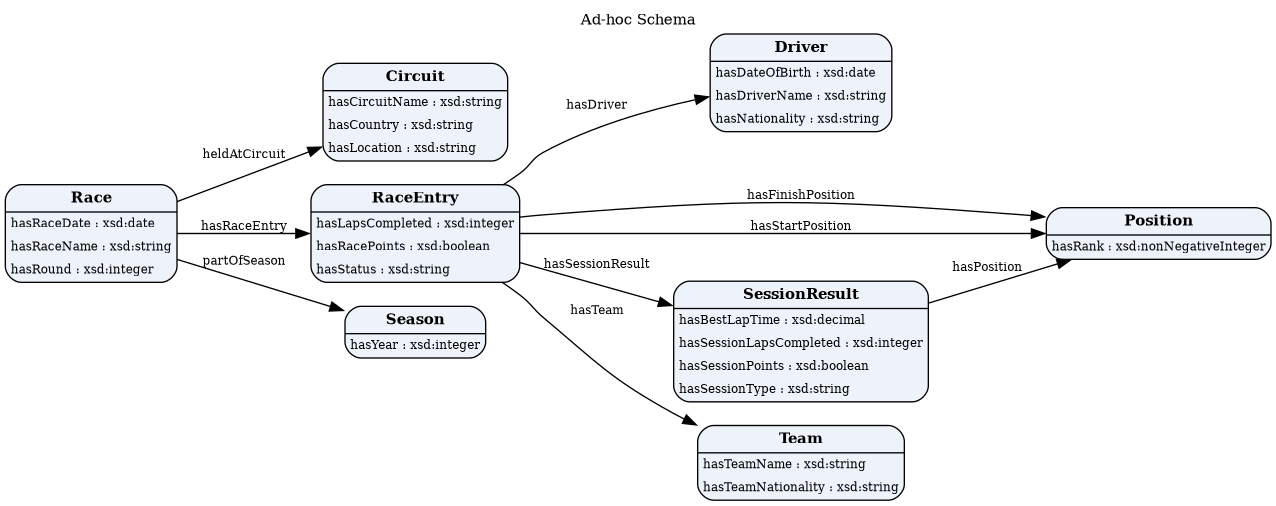

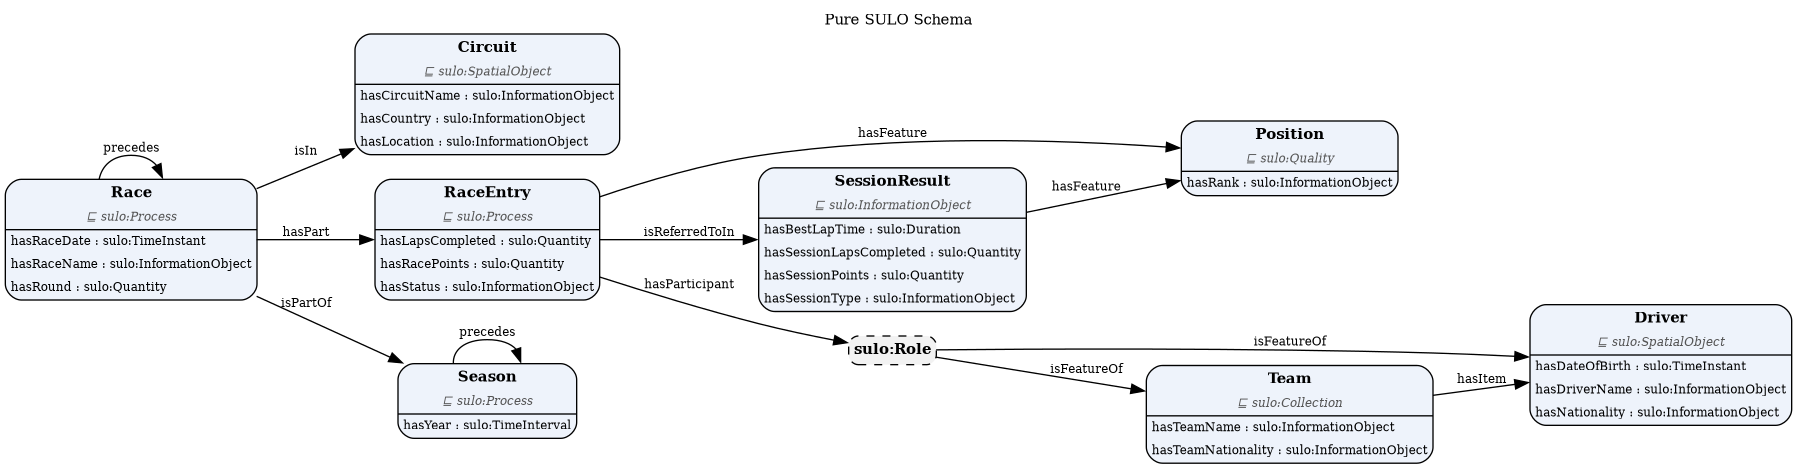

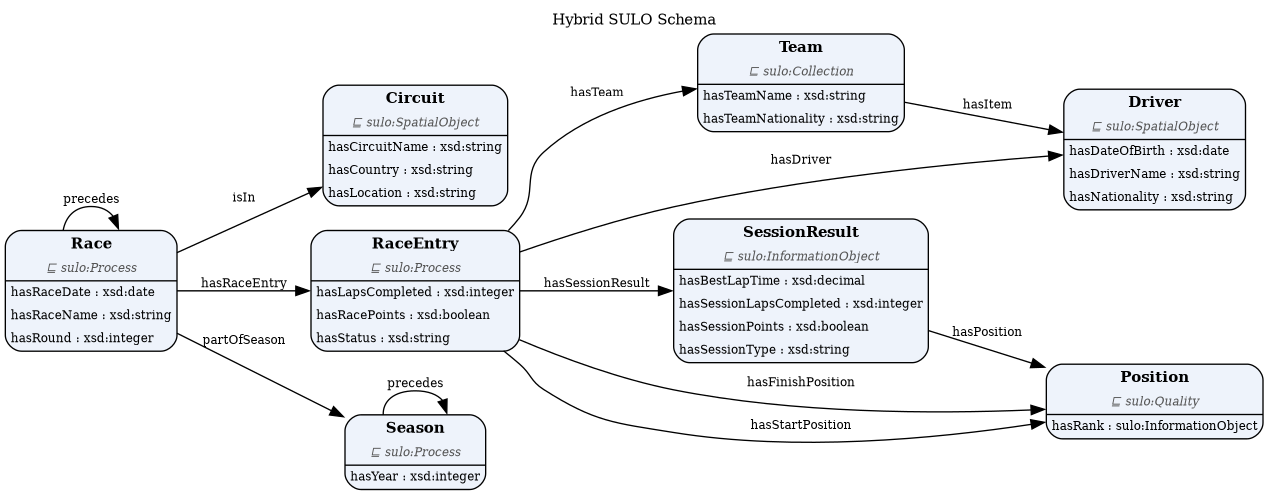

In [ ]:
from IPython.display import Image, display


for key in SCHEMAS:
    display(Image(filename=str(OUT_DIR / f"{key}_schema.png")))